In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the texture coefficients for the four samples to plot.
csv_file = "texture_coefficients.csv"
data = pd.read_csv(csv_file)
samples_to_plot = ["AE_09 e.xy", "L2.xy", "FLA_O.xy", "FLA_Q.xy"]
data = data.set_index("File").loc[samples_to_plot]

coefficient_columns = ["TC(020/200)", "TC(120)", "TC(121/211)"]
tc_values = data[coefficient_columns].copy()
tc_values.columns = ["(020/200)", "(120)", "(121/211)"]
samples = data.index.str.replace(".xy", "", regex=False).tolist()

print(tc_values)


            (020/200)    (120)  (121/211)
File                                     
AE_09 e.xy    1.27972  1.44985    0.27042
L2.xy         1.22474  1.48161    0.29366
FLA_O.xy      1.36179  1.48067    0.15754
FLA_Q.xy      1.45971  1.36715    0.17314


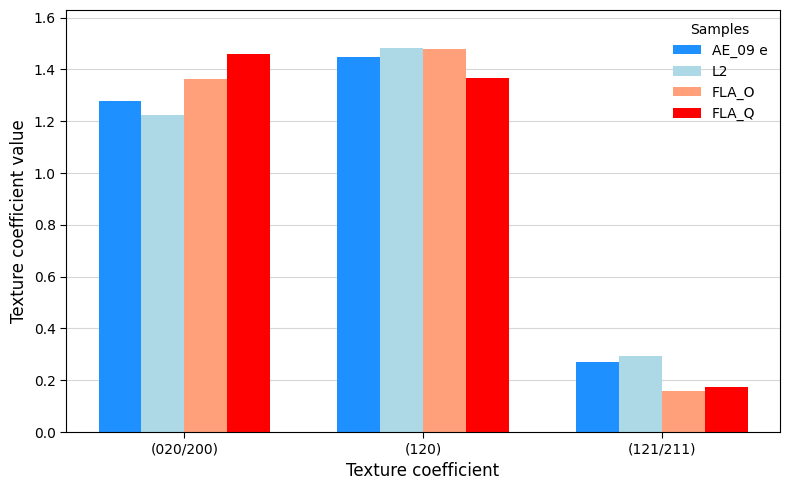

In [ ]:
# Create a grouped bar plot with one bar per sample for each coefficient.
x = np.arange(len(tc_values.columns))
bar_width = 0.18
offsets = (np.arange(len(samples)) - (len(samples) - 1) / 2) * bar_width
colors = ("dodgerblue", "lightblue", "lightsalmon", "red")

fig, ax = plt.subplots(figsize=(8, 5))
for i, sample in enumerate(samples):
    ax.bar(
        x + offsets[i],
        tc_values.iloc[i],
        bar_width,
        label=sample,
        color=colors[i],
    )

ax.set_xlabel("Texture coefficient", fontsize=12, fontname="DejaVu Sans")
ax.set_ylabel("Texture coefficient value", fontsize=12, fontname="DejaVu Sans")
ax.set_xticks(x)
ax.set_xticklabels(tc_values.columns, fontsize=10, fontname="DejaVu Sans")
ax.set_ylim(0, tc_values.to_numpy().max() * 1.1)
ax.legend(title="Samples", fontsize=10, title_fontsize=10, frameon=False)
ax.grid(axis="y", linestyle="-", alpha=0.5)
ax.set_axisbelow(True)
ax.tick_params(axis="both", which="major", labelsize=10, width=0.8, length=4)

plt.tight_layout()
#plt.savefig(r"G:\My Drive\PhD\Research\Sb2S3 papers\XRD figures\Texture coefficients FLA and RTA samples.png", dpi=600) # Uncomment to save
plt.show()
